# Creating and Backtesting RSI Strategies

## Getting the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
%config InlineBackend.figure_format = "retina"

In [3]:
import warnings
warnings.filterwarnings(action = "ignore")

In [4]:
data = pd.read_csv("eurusd.csv", parse_dates = ["Date"], index_col = "Date")

In [5]:
data

,price
Date,
2004-01-01,1.258194
2004-01-02,1.258194
2004-01-05,1.268698
2004-01-06,1.272103
2004-01-07,1.264095
...,...
2020-06-24,1.131235
2020-06-25,1.125087
2020-06-26,1.122208


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4275 entries, 2004-01-01 to 2020-06-30
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   price   4275 non-null   float64
dtypes: float64(1)
memory usage: 66.8 KB


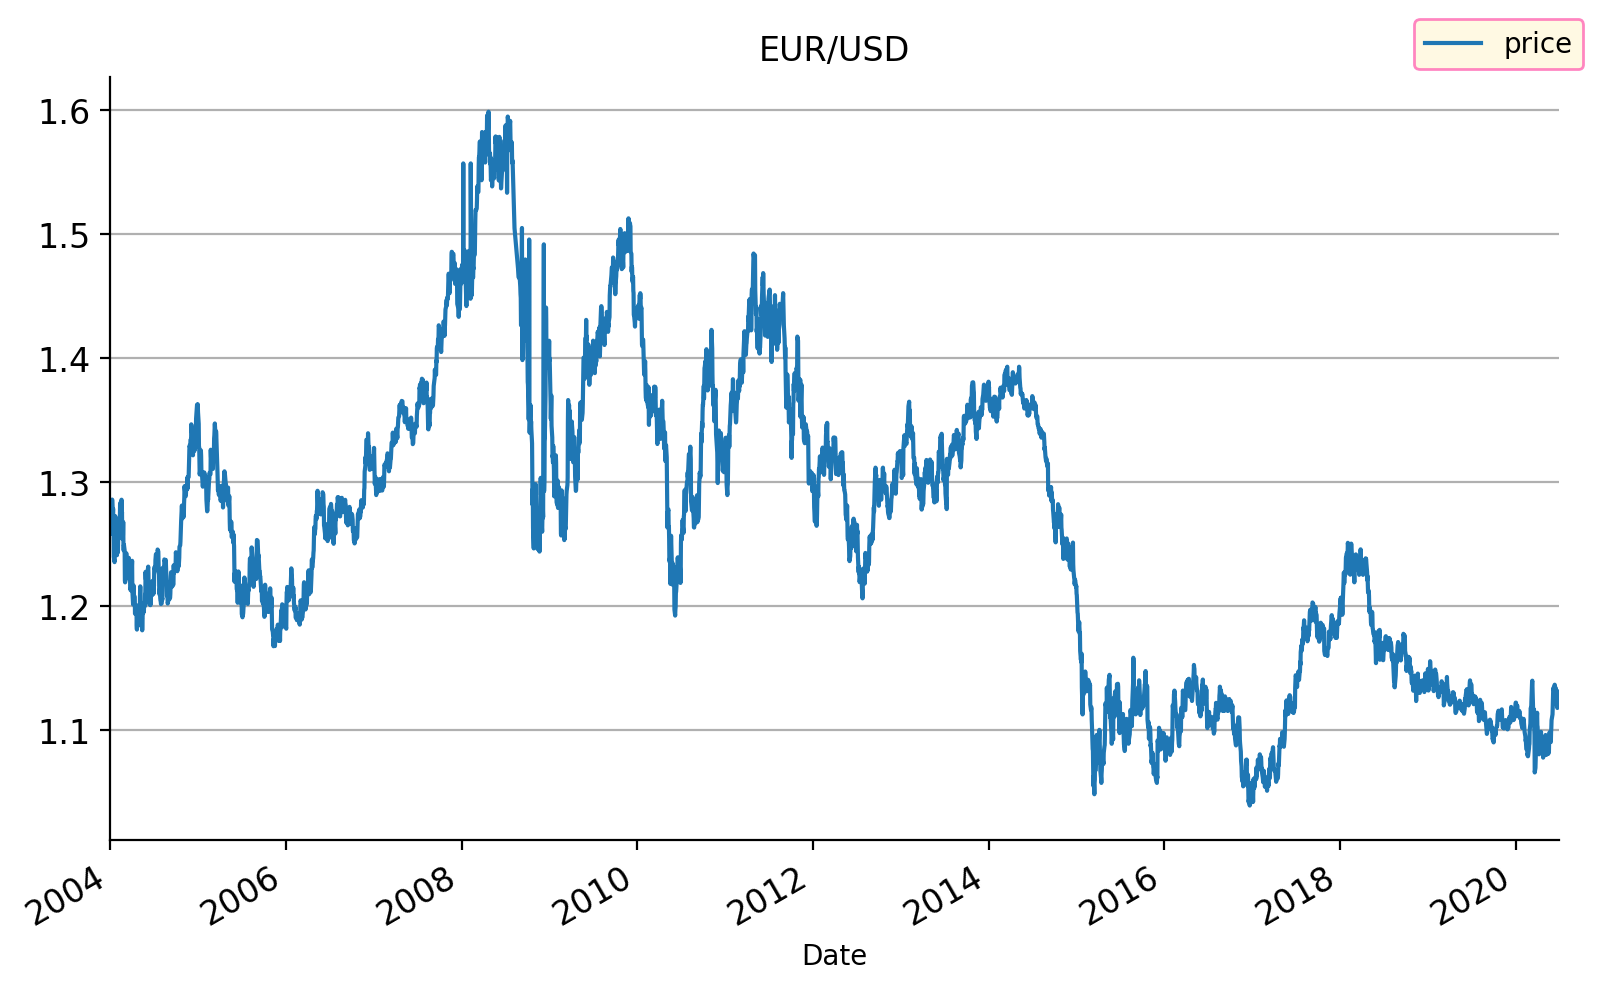

In [16]:
data.plot(figsize = (8, 5), title = "EUR/USD", fontsize = 12).autoscale(enable=True , axis ="x" , tight = True)
plt.gca().spines[["right" , "top"]].set_visible(False)
plt.grid(axis ="y")
plt.tight_layout()
plt.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
plt.show()

## Defining an RSI Strategy (Part 1)

In [17]:
data

,price
Date,
2004-01-01,1.258194
2004-01-02,1.258194
2004-01-05,1.268698
2004-01-06,1.272103
2004-01-07,1.264095
...,...
2020-06-24,1.131235
2020-06-25,1.125087
2020-06-26,1.122208


In [18]:
data.price.diff()

Date
2004-01-01         NaN
2004-01-02    0.000000
2004-01-05    0.010504
2004-01-06    0.003405
2004-01-07   -0.008008
                ...   
2020-06-24    0.003267
2020-06-25   -0.006147
2020-06-26   -0.002879
2020-06-29    0.000378
2020-06-30    0.002134
Name: price, Length: 4275, dtype: float64

__U:__ <br>
- if __positive__ price change ("up"): __price change__<br>
- if __negative__ price change ("down"): __0__

In [19]:
data["U"] = np.where(data["price"].diff()>0 , data["price"].diff() , 0)

In [20]:
data

,price,U
Date,,
2004-01-01,1.258194,0.000000
2004-01-02,1.258194,0.000000
2004-01-05,1.268698,0.010504
2004-01-06,1.272103,0.003405
2004-01-07,1.264095,0.000000
...,...,...
2020-06-24,1.131235,0.003267
2020-06-25,1.125087,0.000000
2020-06-26,1.122208,0.000000


__D:__ <br>
- if __positive__ price change ("up"): __0__<br>
- if __negative__ price change ("down"): __-price change__

In [21]:
data["D"] = np.where(data["price"].diff() < 0 , -data["price"].diff() , 0)

In [22]:
data

,price,U,D
Date,,,
2004-01-01,1.258194,0.000000,0.000000
2004-01-02,1.258194,0.000000,0.000000
2004-01-05,1.268698,0.010504,0.000000
2004-01-06,1.272103,0.003405,0.000000
2004-01-07,1.264095,0.000000,0.008008
...,...,...,...
2020-06-24,1.131235,0.003267,0.000000
2020-06-25,1.125087,0.000000,0.006147
2020-06-26,1.122208,0.000000,0.002879


__Calculate Moving Averages for U and D__ (alternative: exponential smoothing)

In [23]:
periods = 20

In [24]:
data["MA_U"] = data["U"].rolling(window=periods).mean()
data["MA_D"] = data["D"].rolling(window=periods).mean()

In [25]:
data

,price,U,D,MA_U,MA_D
Date,,,,,
2004-01-01,1.258194,0.000000,0.000000,NaN,NaN
2004-01-02,1.258194,0.000000,0.000000,NaN,NaN
2004-01-05,1.268698,0.010504,0.000000,NaN,NaN
2004-01-06,1.272103,0.003405,0.000000,NaN,NaN
2004-01-07,1.264095,0.000000,0.008008,NaN,NaN
...,...,...,...,...,...
2020-06-24,1.131235,0.003267,0.000000,0.003182,0.001530
2020-06-25,1.125087,0.000000,0.006147,0.003007,0.001837
2020-06-26,1.122208,0.000000,0.002879,0.002696,0.001981


__Calculate Relative Strength Index (RSI)__

Ratio of ups to downs

In [26]:
data["RSI"] = data["MA_U"] / (data["MA_U"] + data["MA_D"])
data["RSI"] = data["RSI"] * 100

In [28]:
data = data.dropna()

In [29]:
data

,price,U,D,MA_U,MA_D,RSI
Date,,,,,,
2004-01-28,1.244199,0.000000,0.019496,0.004610,0.005310,46.472973
2004-01-29,1.241003,0.000000,0.003196,0.004610,0.005470,45.736150
2004-01-30,1.246805,0.005802,0.000000,0.004900,0.005470,47.254310
2004-02-02,1.243302,0.000000,0.003503,0.004375,0.005645,43.663573
2004-02-03,1.253494,0.010192,0.000000,0.004714,0.005645,45.509086
...,...,...,...,...,...,...
2020-06-24,1.131235,0.003267,0.000000,0.003182,0.001530,67.538713
2020-06-25,1.125087,0.000000,0.006147,0.003007,0.001837,62.077668
2020-06-26,1.122208,0.000000,0.002879,0.002696,0.001981,57.643190


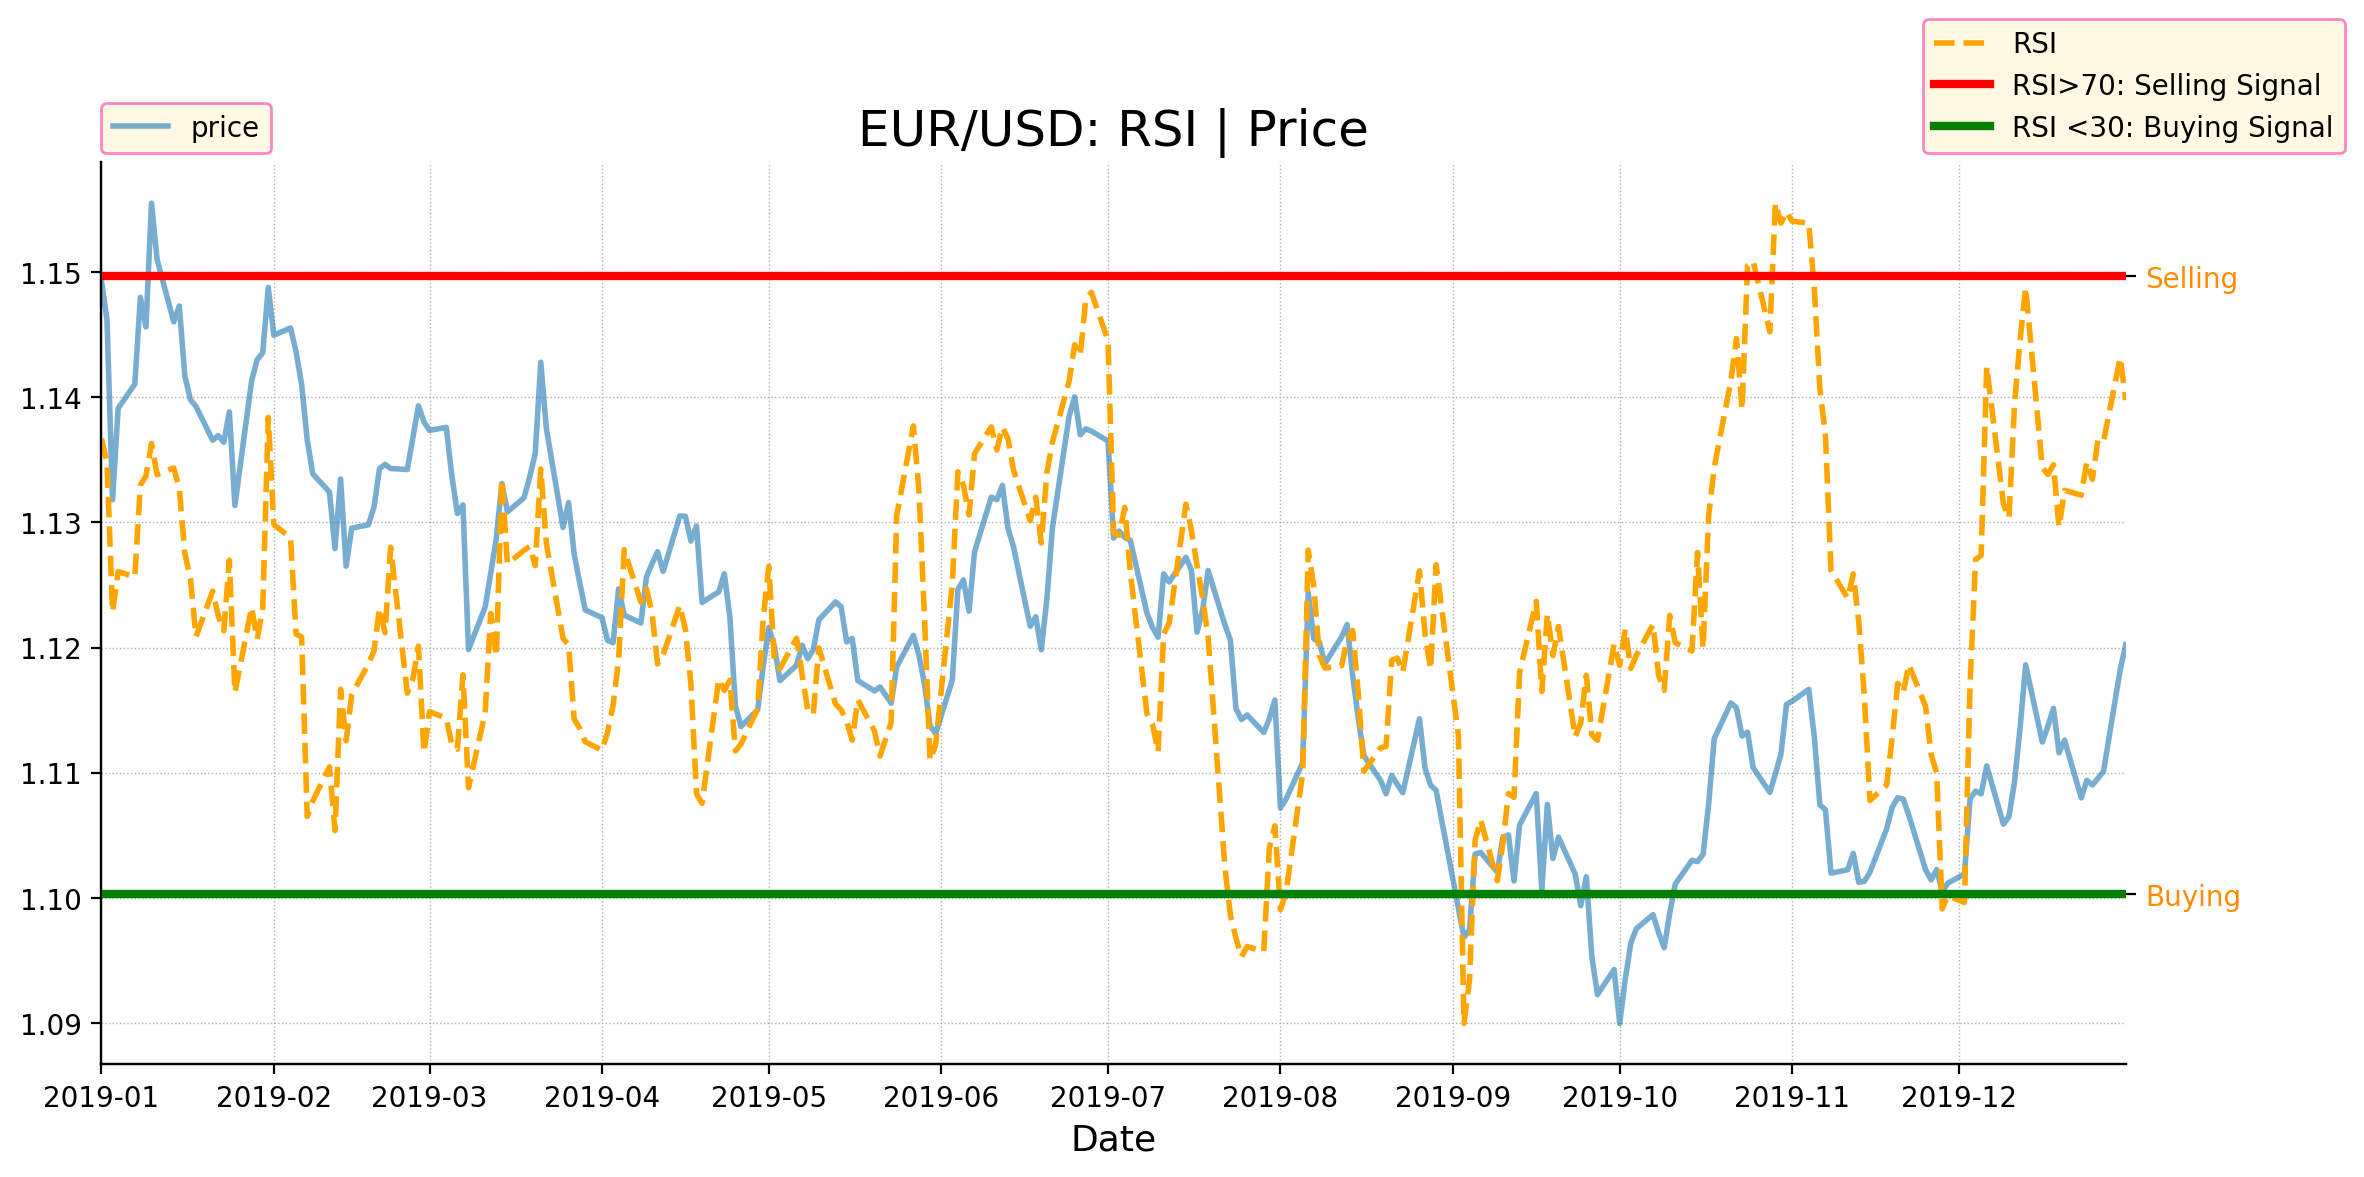

In [72]:
fig , ax = plt.subplots(figsize = (12,6))

ax.plot(data.loc["2019", ["price"]] , label = "price" , lw = 2 , alpha = .6)
ax.spines[["right" , "top"]].set_visible(False)
ax.legend(loc = (0.,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
ax.autoscale(enable=True , axis ="x" , tight = True)
ax.set_xlabel("Date" , fontsize = 13)
ax.set_title(f"EUR/USD: RSI | Price" , fontsize = 18)
ax.grid(ls = ":", lw= .5)

ax2 = ax.twinx()
ax2.plot(data.loc["2019", ["RSI"]] , label = "RSI" , color = "orange" , ls ="--" , lw = 2)
ax2.spines[["right" , "top"]].set_visible(False)
ax2.autoscale(enable=True , axis ="x" , tight = True)
ax2.axhline(y=70 , color = "red" , label = "RSI>70: Selling Signal" , lw = 3)
ax2.axhline(y=30 , color = "green" , label = "RSI <30: Buying Signal" , lw = 3)
ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
ax2.set_yticks(ticks = [30,70] , labels = ["Buying" , "Selling"], color = "darkorange")

plt.tight_layout()
plt.show()

Instruments which have had
- __more or stronger positive changes__ have a __higher RSI__
- __more or stronger negative changes__ have a __lower RSI__

## Defining an RSI Strategy (Part 2)

- Extreme __high RSI__ (>70) indicates __overbought__ instrument -> __sell__
- Extreme __low RSI__ (<30) indicates __oversold__ instrument -> __buy__ 

In [73]:
rsi_upper = 70
rsi_lower = 30

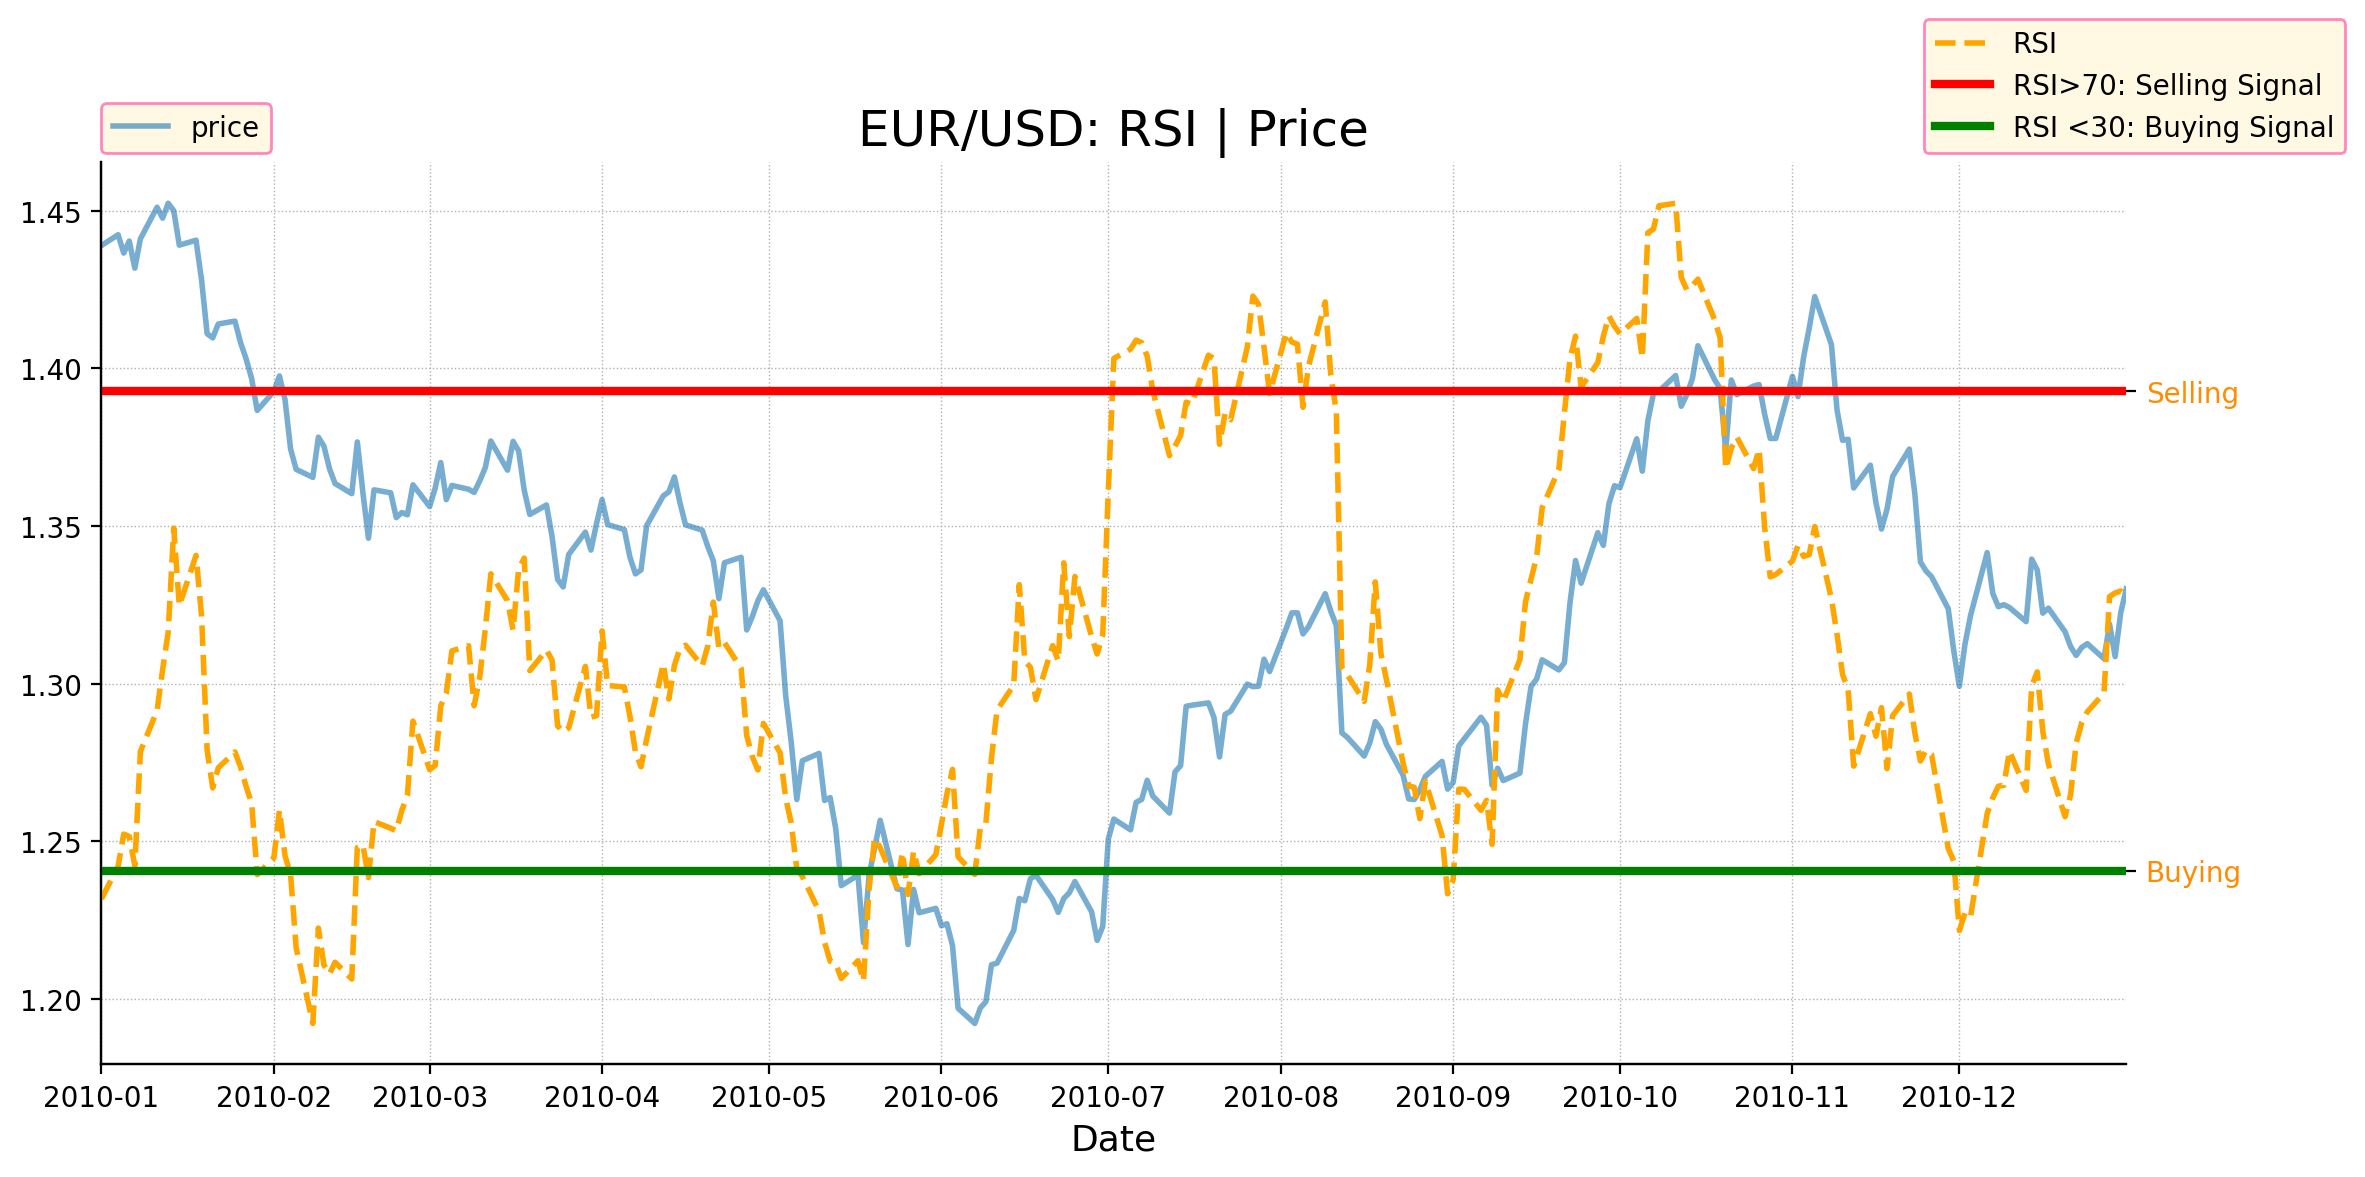

In [77]:
fig , ax = plt.subplots(figsize = (12,6))

ax.plot(data.loc["2010", ["price"]] , label = "price" , lw = 2 , alpha = .6)
ax.spines[["right" , "top"]].set_visible(False)
ax.legend(loc = (0.,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
ax.autoscale(enable=True , axis ="x" , tight = True)
ax.set_xlabel("Date" , fontsize = 13)
ax.set_title(f"EUR/USD: RSI | Price" , fontsize = 18)
ax.grid(ls = ":", lw= .5)

ax2 = ax.twinx()
ax2.plot(data.loc["2010", ["RSI"]] , label = "RSI" , color = "orange" , ls ="--" , lw = 2)
ax2.spines[["right" , "top"]].set_visible(False)
ax2.autoscale(enable=True , axis ="x" , tight = True)
ax2.axhline(y = rsi_upper , color = "red" , label = f"RSI>{rsi_upper}: Selling Signal" , lw = 3)
ax2.axhline(y = rsi_lower , color = "green" , label = f"RSI <{rsi_lower}: Buying Signal" , lw = 3)
ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
ax2.set_yticks(ticks = [30,70] , labels = ["Buying" , "Selling"], color = "darkorange")

plt.tight_layout()
plt.show()

In [ ]:
np.where(data["RSI"] > rsi_upper , -1 , np.where(data["RSI"] < rsi_lower , +1 , 0))

array([0, 0, 0, ..., 0, 0, 0])

In [ ]:
np.unique(np.where(data["RSI"] > rsi_upper , -1 , np.where(data["RSI"] < rsi_lower , +1 , 0)))

array([-1,  0,  1])

In [80]:
len(np.where(data["RSI"] > rsi_upper , -1 , np.where(data["RSI"] < rsi_lower , +1 , 0)))

4256

In [93]:
# data["position2"] = np.where(data["RSI"] > rsi_upper , -1 , np.where(data["RSI"] < rsi_lower , +1 , 0))
# data["position2"] = np.where(data.RSI > rsi_upper, -1, np.nan) # 1. overbought -> go short
# data["position2"] = np.where(data.RSI < rsi_lower, 1, data.position) # 2. oversold -> go long
# data["position2"] = data.position.fillna(0) # 3. where 1 & 2 isn´t applicable -> neutral

In [90]:
data["position"] = np.where(data["RSI"] > rsi_upper , -1 , np.where(data["RSI"] < rsi_lower , +1 , 0))

In [91]:
data["position"].value_counts()

 0    3637
-1     316
 1     303
Name: position, dtype: int64

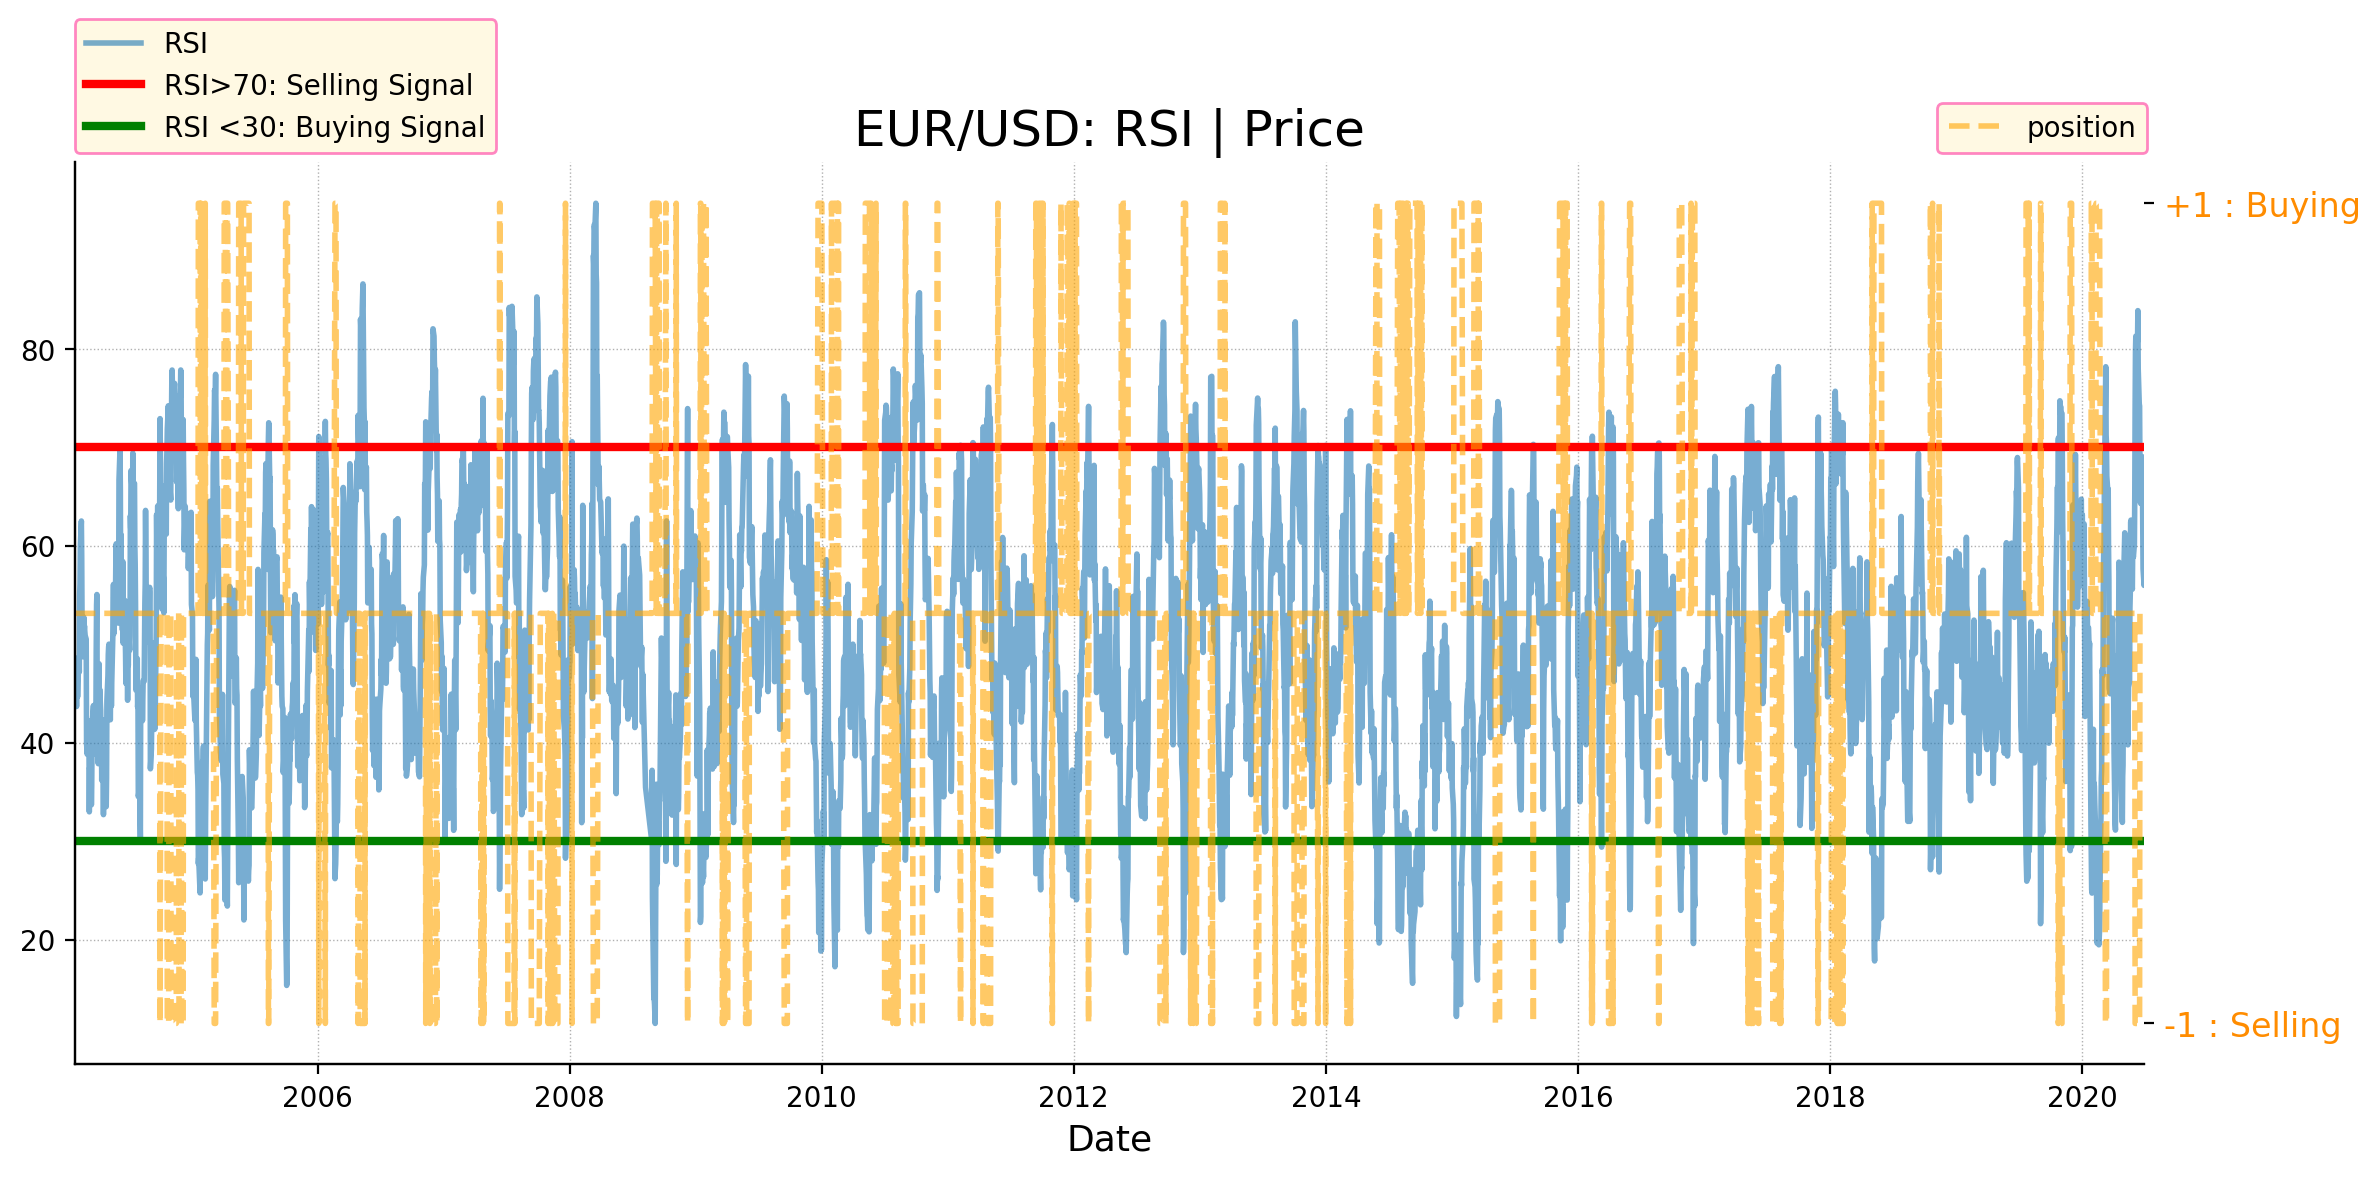

In [104]:
fig , ax = plt.subplots(figsize = (12,6))

ax.plot(data.loc[:, ["RSI"]] , label = "RSI" , lw = 2 , alpha = .6)
ax.spines[["right" , "top"]].set_visible(False)
ax.axhline(y = rsi_upper , color = "red" , label = f"RSI>{rsi_upper}: Selling Signal" , lw = 3)
ax.axhline(y = rsi_lower , color = "green" , label = f"RSI <{rsi_lower}: Buying Signal" , lw = 3)
ax.autoscale(enable=True , axis ="x" , tight = True)
ax.legend(loc = (0.,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
ax.set_xlabel("Date" , fontsize = 13)
ax.set_title(f"EUR/USD: RSI | Price" , fontsize = 18)
ax.grid(ls = ":", lw= .5)

ax2 = ax.twinx()
ax2.plot(data.loc[:, ["position"]] , label = "position" , color = "orange", alpha = .6 , ls ="--" , lw = 2)
ax2.spines[["right" , "top"]].set_visible(False)
ax2.autoscale(enable=True , axis ="x" , tight = True)
ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
ax2.set_yticks(ticks = [-1 , +1] , labels = ["-1 : Selling" , "+1 : Buying"], color = "darkorange" , fontsize = 12)

plt.tight_layout()
plt.show()

In [119]:
data.loc["06-2010":"07-2010"].index

DatetimeIndex(['2010-06-01', '2010-06-02', '2010-06-03', '2010-06-04',
               '2010-06-07', '2010-06-08', '2010-06-09', '2010-06-10',
               '2010-06-11', '2010-06-14', '2010-06-15', '2010-06-16',
               '2010-06-17', '2010-06-18', '2010-06-21', '2010-06-22',
               '2010-06-23', '2010-06-24', '2010-06-25', '2010-06-28',
               '2010-06-29', '2010-06-30', '2010-07-01', '2010-07-02',
               '2010-07-05', '2010-07-06', '2010-07-07', '2010-07-08',
               '2010-07-09', '2010-07-12', '2010-07-13', '2010-07-14',
               '2010-07-15', '2010-07-16', '2010-07-19', '2010-07-20',
               '2010-07-21', '2010-07-22', '2010-07-23', '2010-07-26',
               '2010-07-27', '2010-07-28', '2010-07-29', '2010-07-30'],
              dtype='datetime64[ns]', name='Date', freq=None)

In [127]:
#y1 = 70

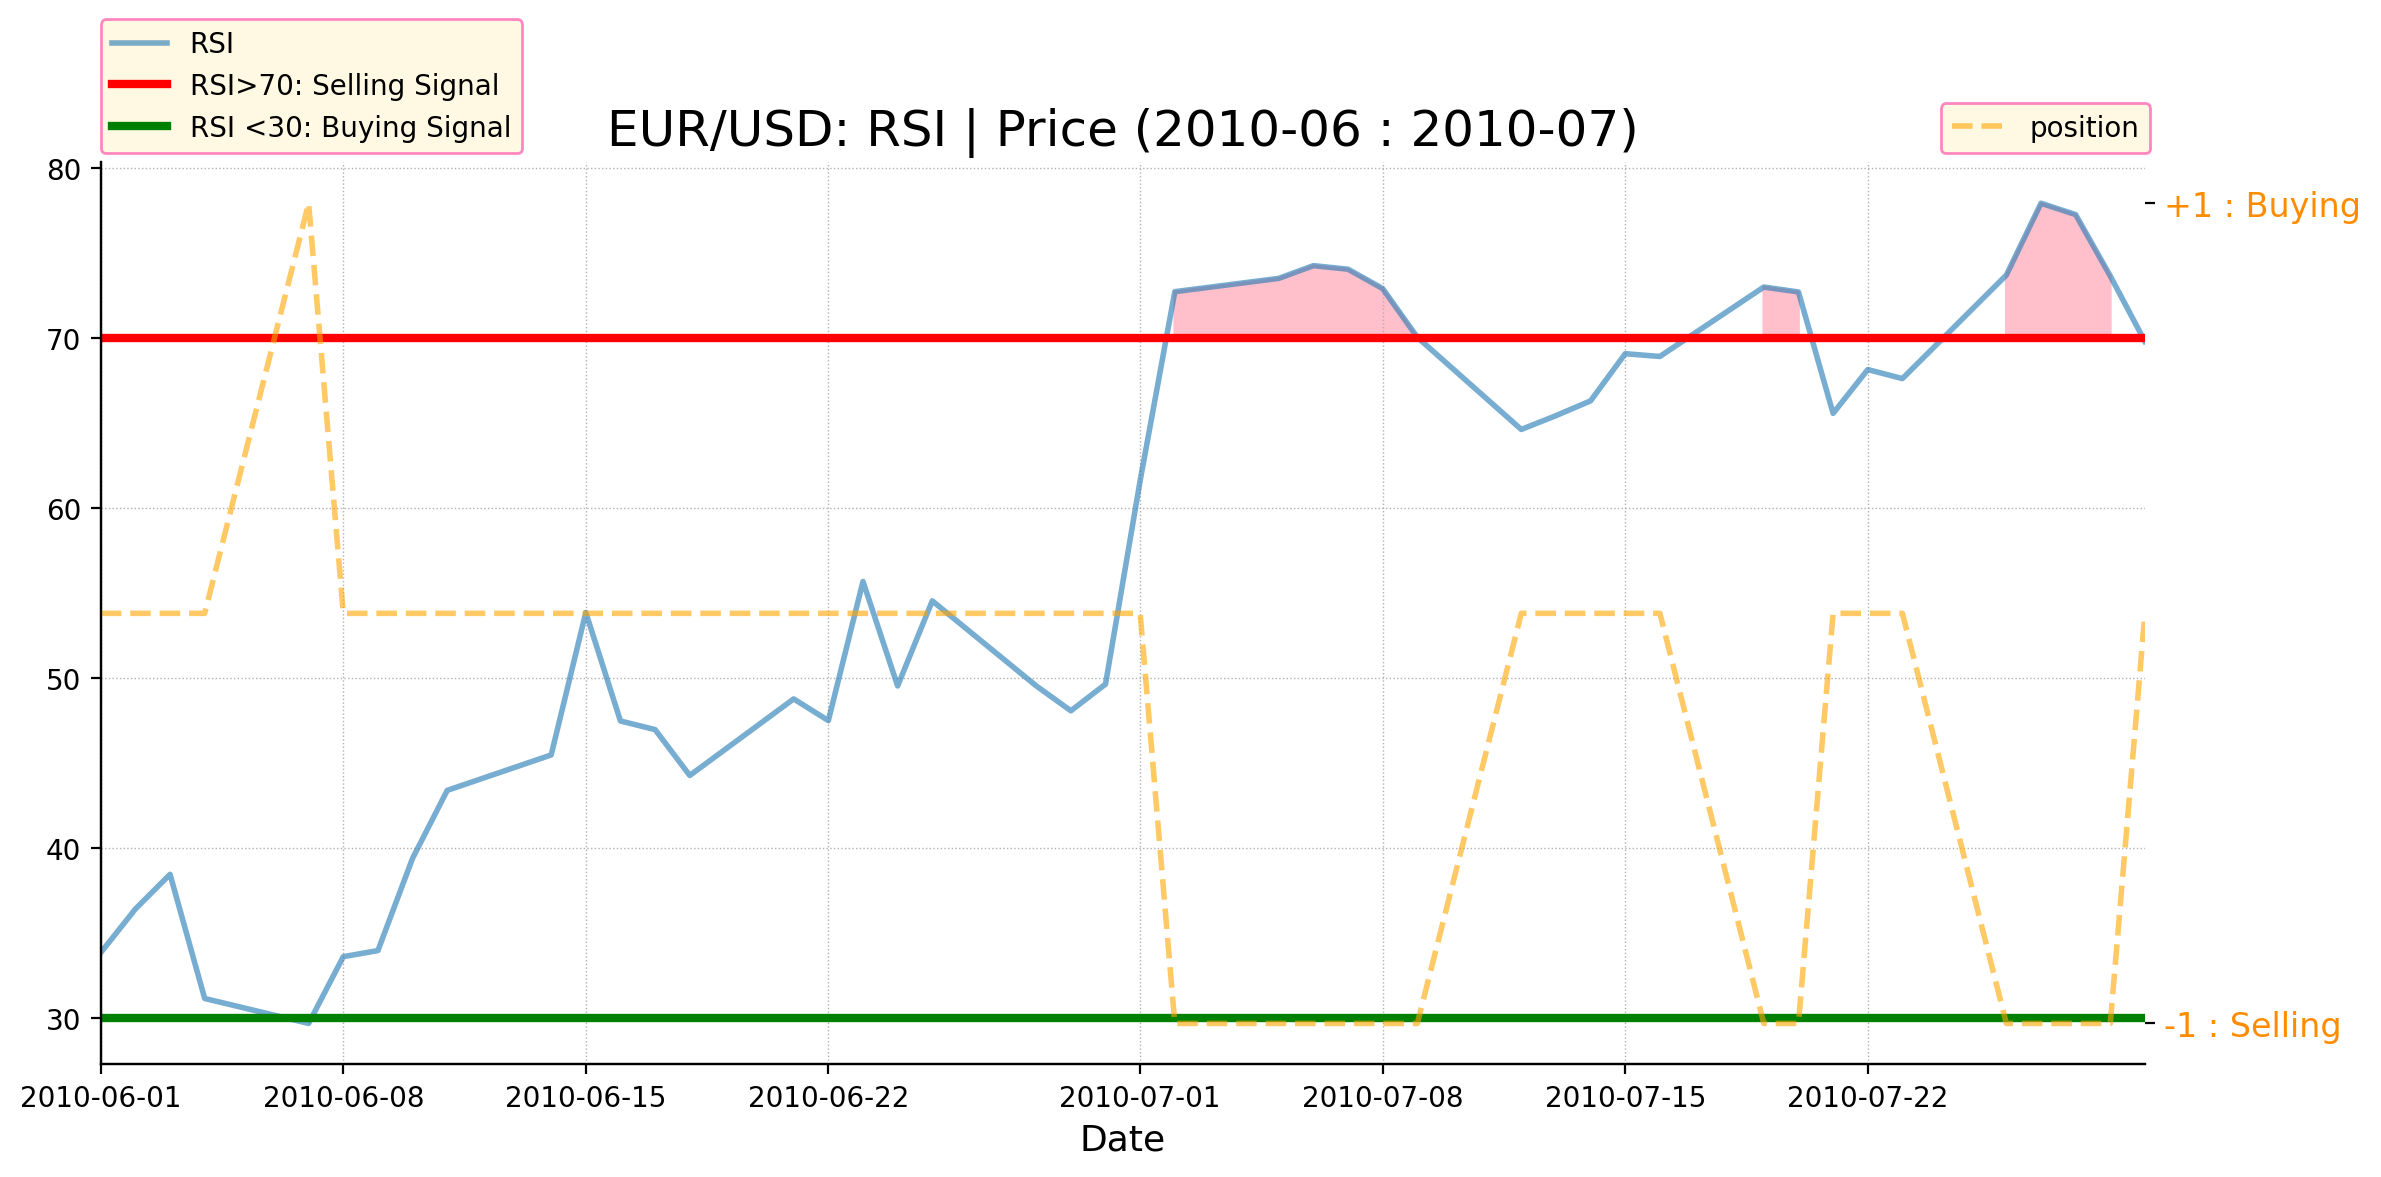

In [153]:
fig , ax = plt.subplots(figsize = (12,6))

ax.plot(data.loc["06-2010":"07-2010", ["RSI"]] , label = "RSI" , lw = 2 , alpha = .6)
ax.spines[["right" , "top"]].set_visible(False)
ax.axhline(y = rsi_upper , color = "red" , label = f"RSI>{rsi_upper}: Selling Signal" , lw = 3)
ax.axhline(y = rsi_lower , color = "green" , label = f"RSI <{rsi_lower}: Buying Signal" , lw = 3)
ax.fill_between(y1 = 70, y2 = data.loc["06-2010":"07-2010", "RSI"] , x = data.loc["06-2010":"07-2010"].index , where = (data.loc["06-2010":"07-2010", "RSI"] >= 70) , color = "pink")
ax.fill_between(y1 = 30, y2 = data.loc["06-2010":"07-2010", "RSI"] , x = data.loc["06-2010":"07-2010"].index , where = (data.loc["06-2010":"07-2010", "RSI"] <= 30) , color = "palegreen")

ax.autoscale(enable=True , axis ="x" , tight = True)
ax.legend(loc = (0.,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
ax.set_xlabel("Date" , fontsize = 13)
ax.set_title(f"EUR/USD: RSI | Price (2010-06 : 2010-07)" , fontsize = 18)
ax.grid(ls = ":", lw= .5)

ax2 = ax.twinx()
ax2.plot(data.loc["06-2010":"07-2010":, ["position"]] , label = "position" , color = "orange", alpha = .6 , ls ="--" , lw = 2)
ax2.spines[["right" , "top"]].set_visible(False)
ax2.autoscale(enable=True , axis ="x" , tight = True)
ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
ax2.set_yticks(ticks = [-1 , +1] , labels = ["-1 : Selling" , "+1 : Buying"], color = "darkorange" , fontsize = 12)

plt.tight_layout()
plt.show()

## Vectorized Strategy Backtesting

In [154]:
data

,price,U,D,MA_U,MA_D,RSI,position
Date,,,,,,,
2004-01-28,1.244199,0.000000,0.019496,0.004610,0.005310,46.472973,0
2004-01-29,1.241003,0.000000,0.003196,0.004610,0.005470,45.736150,0
2004-01-30,1.246805,0.005802,0.000000,0.004900,0.005470,47.254310,0
2004-02-02,1.243302,0.000000,0.003503,0.004375,0.005645,43.663573,0
2004-02-03,1.253494,0.010192,0.000000,0.004714,0.005645,45.509086,0
...,...,...,...,...,...,...,...
2020-06-24,1.131235,0.003267,0.000000,0.003182,0.001530,67.538713,0
2020-06-25,1.125087,0.000000,0.006147,0.003007,0.001837,62.077668,0
2020-06-26,1.122208,0.000000,0.002879,0.002696,0.001981,57.643190,0


In [155]:
data["position"].value_counts()

 0    3637
-1     316
 1     303
Name: position, dtype: int64

In [156]:
data["log_ret"] = np.log(data["price"]/data["price"].shift(1))

In [157]:
data = data.dropna()

In [158]:
data

,price,U,D,MA_U,MA_D,RSI,position,log_ret
Date,,,,,,,,
2004-01-29,1.241003,0.000000,0.003196,0.004610,0.005470,45.736150,0,-0.002572
2004-01-30,1.246805,0.005802,0.000000,0.004900,0.005470,47.254310,0,0.004665
2004-02-02,1.243302,0.000000,0.003503,0.004375,0.005645,43.663573,0,-0.002814
2004-02-03,1.253494,0.010192,0.000000,0.004714,0.005645,45.509086,0,0.008164
2004-02-04,1.253997,0.000503,0.000000,0.004740,0.005244,47.471521,0,0.000401
...,...,...,...,...,...,...,...,...
2020-06-24,1.131235,0.003267,0.000000,0.003182,0.001530,67.538713,0,0.002892
2020-06-25,1.125087,0.000000,0.006147,0.003007,0.001837,62.077668,0,-0.005449
2020-06-26,1.122208,0.000000,0.002879,0.002696,0.001981,57.643190,0,-0.002562


In [160]:
data["strategy"] = data["position"].shift(1) * data["log_ret"]

In [161]:
data = data.dropna()

In [162]:
data

,price,U,D,MA_U,MA_D,RSI,position,log_ret,strategy
Date,,,,,,,,,
2004-01-30,1.246805,0.005802,0.000000,0.004900,0.005470,47.254310,0,0.004665,0.0
2004-02-02,1.243302,0.000000,0.003503,0.004375,0.005645,43.663573,0,-0.002814,-0.0
2004-02-03,1.253494,0.010192,0.000000,0.004714,0.005645,45.509086,0,0.008164,0.0
2004-02-04,1.253997,0.000503,0.000000,0.004740,0.005244,47.471521,0,0.000401,0.0
2004-02-05,1.257197,0.003200,0.000000,0.004229,0.005244,44.642922,0,0.002549,0.0
...,...,...,...,...,...,...,...,...,...
2020-06-24,1.131235,0.003267,0.000000,0.003182,0.001530,67.538713,0,0.002892,0.0
2020-06-25,1.125087,0.000000,0.006147,0.003007,0.001837,62.077668,0,-0.005449,-0.0
2020-06-26,1.122208,0.000000,0.002879,0.002696,0.001981,57.643190,0,-0.002562,-0.0


In [163]:
ptc = 0.00007

In [164]:
data["trades"] = data["position"].diff().fillna(0).abs()

In [165]:
data["trades"].value_counts()

0.0    3926
1.0     328
Name: trades, dtype: int64

In [166]:
data["strategy_net"] = data["strategy"] - data["trades"] * ptc

In [168]:
data["cum_ret"] = np.exp(data["log_ret"].cumsum())
data["cum_strategy"] = np.exp(data["strategy"].cumsum())
data["cum_strategy_net"] = np.exp(data["strategy_net"].cumsum())

In [169]:
data

,price,U,D,MA_U,MA_D,RSI,position,log_ret,strategy,trades,strategy_net,cum_ret,cum_strategy,cum_strategy_net
Date,,,,,,,,,,,,,,
2004-01-30,1.246805,0.005802,0.000000,0.004900,0.005470,47.254310,0,0.004665,0.0,0.0,0.0,1.004676,1.000000,1.000000
2004-02-02,1.243302,0.000000,0.003503,0.004375,0.005645,43.663573,0,-0.002814,-0.0,0.0,-0.0,1.001852,1.000000,1.000000
2004-02-03,1.253494,0.010192,0.000000,0.004714,0.005645,45.509086,0,0.008164,0.0,0.0,0.0,1.010066,1.000000,1.000000
2004-02-04,1.253997,0.000503,0.000000,0.004740,0.005244,47.471521,0,0.000401,0.0,0.0,0.0,1.010471,1.000000,1.000000
2004-02-05,1.257197,0.003200,0.000000,0.004229,0.005244,44.642922,0,0.002549,0.0,0.0,0.0,1.013050,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-06-24,1.131235,0.003267,0.000000,0.003182,0.001530,67.538713,0,0.002892,0.0,0.0,0.0,0.911549,1.562978,1.527501
2020-06-25,1.125087,0.000000,0.006147,0.003007,0.001837,62.077668,0,-0.005449,-0.0,0.0,-0.0,0.906595,1.562978,1.527501
2020-06-26,1.122208,0.000000,0.002879,0.002696,0.001981,57.643190,0,-0.002562,-0.0,0.0,-0.0,0.904276,1.562978,1.527501


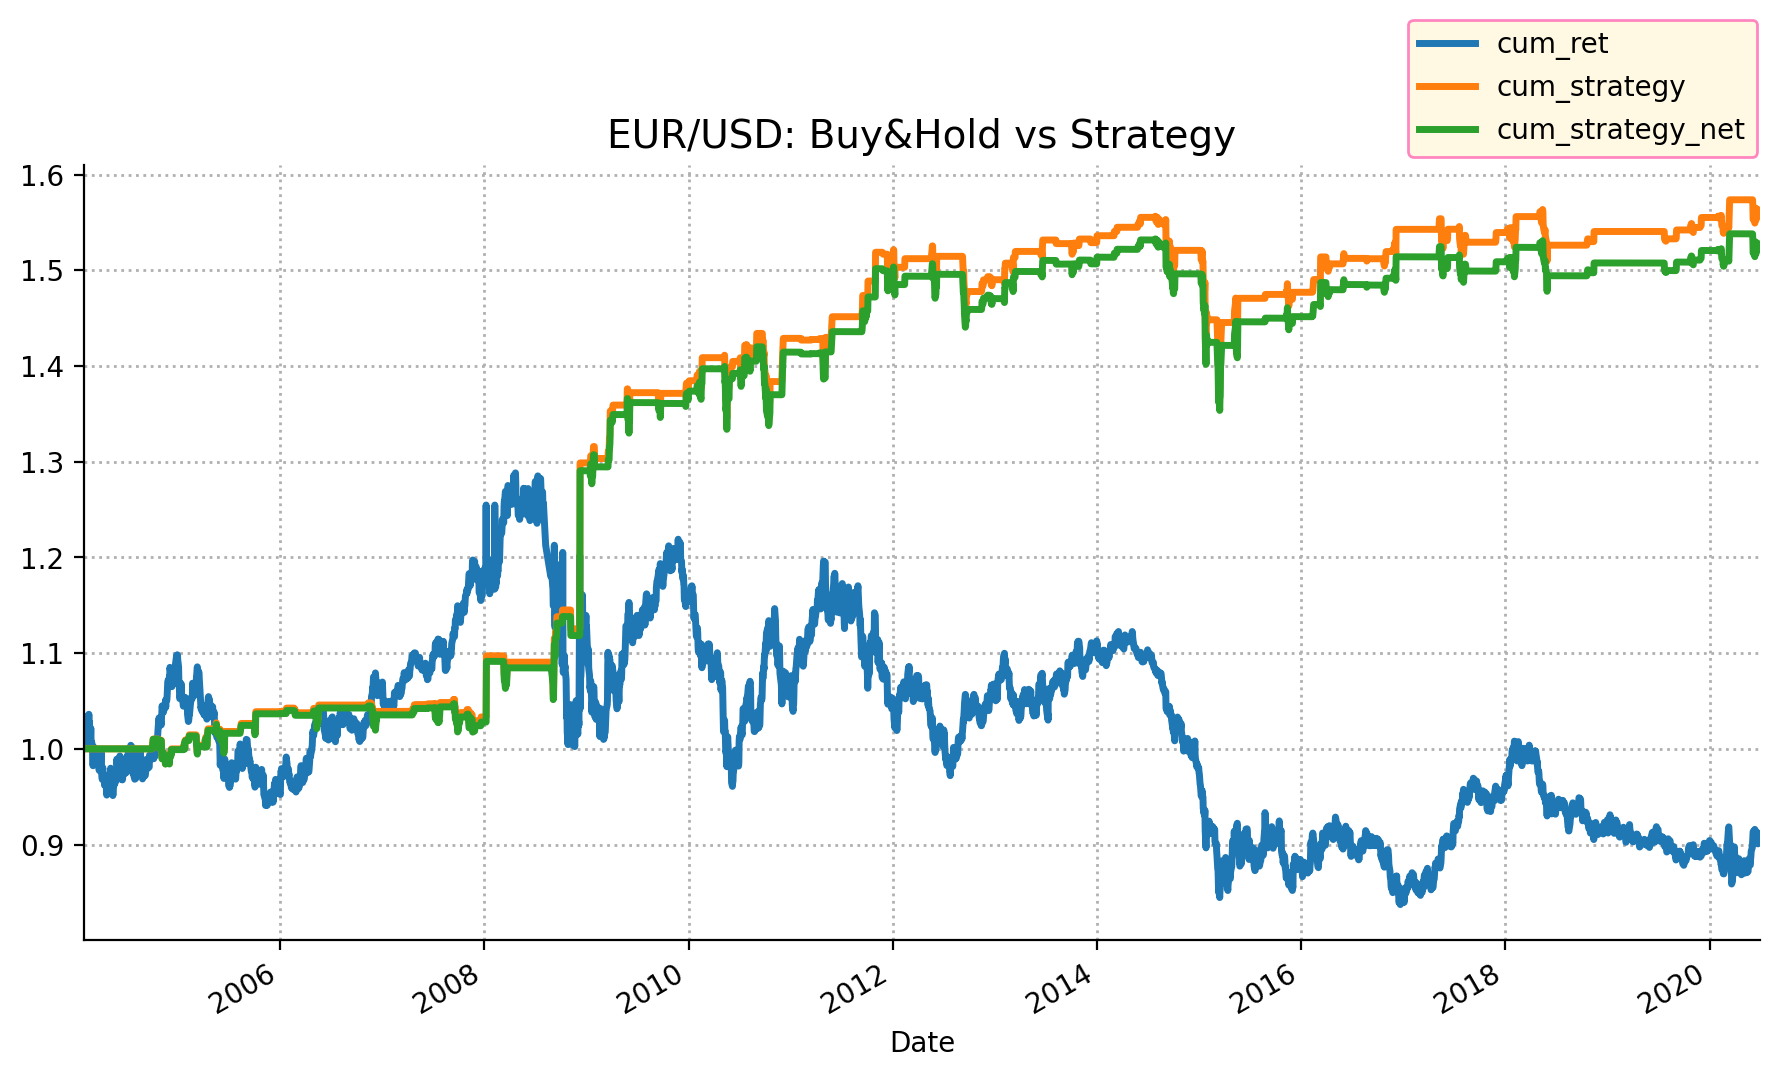

In [191]:
data[["cum_ret", "cum_strategy", "cum_strategy_net"]].plot(figsize = (9 , 5) , lw = 2.5).autoscale(enable=True, tight = True , axis = "x")
plt.title("EUR/USD: Buy&Hold vs Strategy" , fontsize = 14)
plt.gca().spines[["right" , "top"]].set_visible(False)
plt.grid( ls = ":", lw = 1)
plt.tight_layout()
plt.legend(loc = (0.79,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
plt.show()

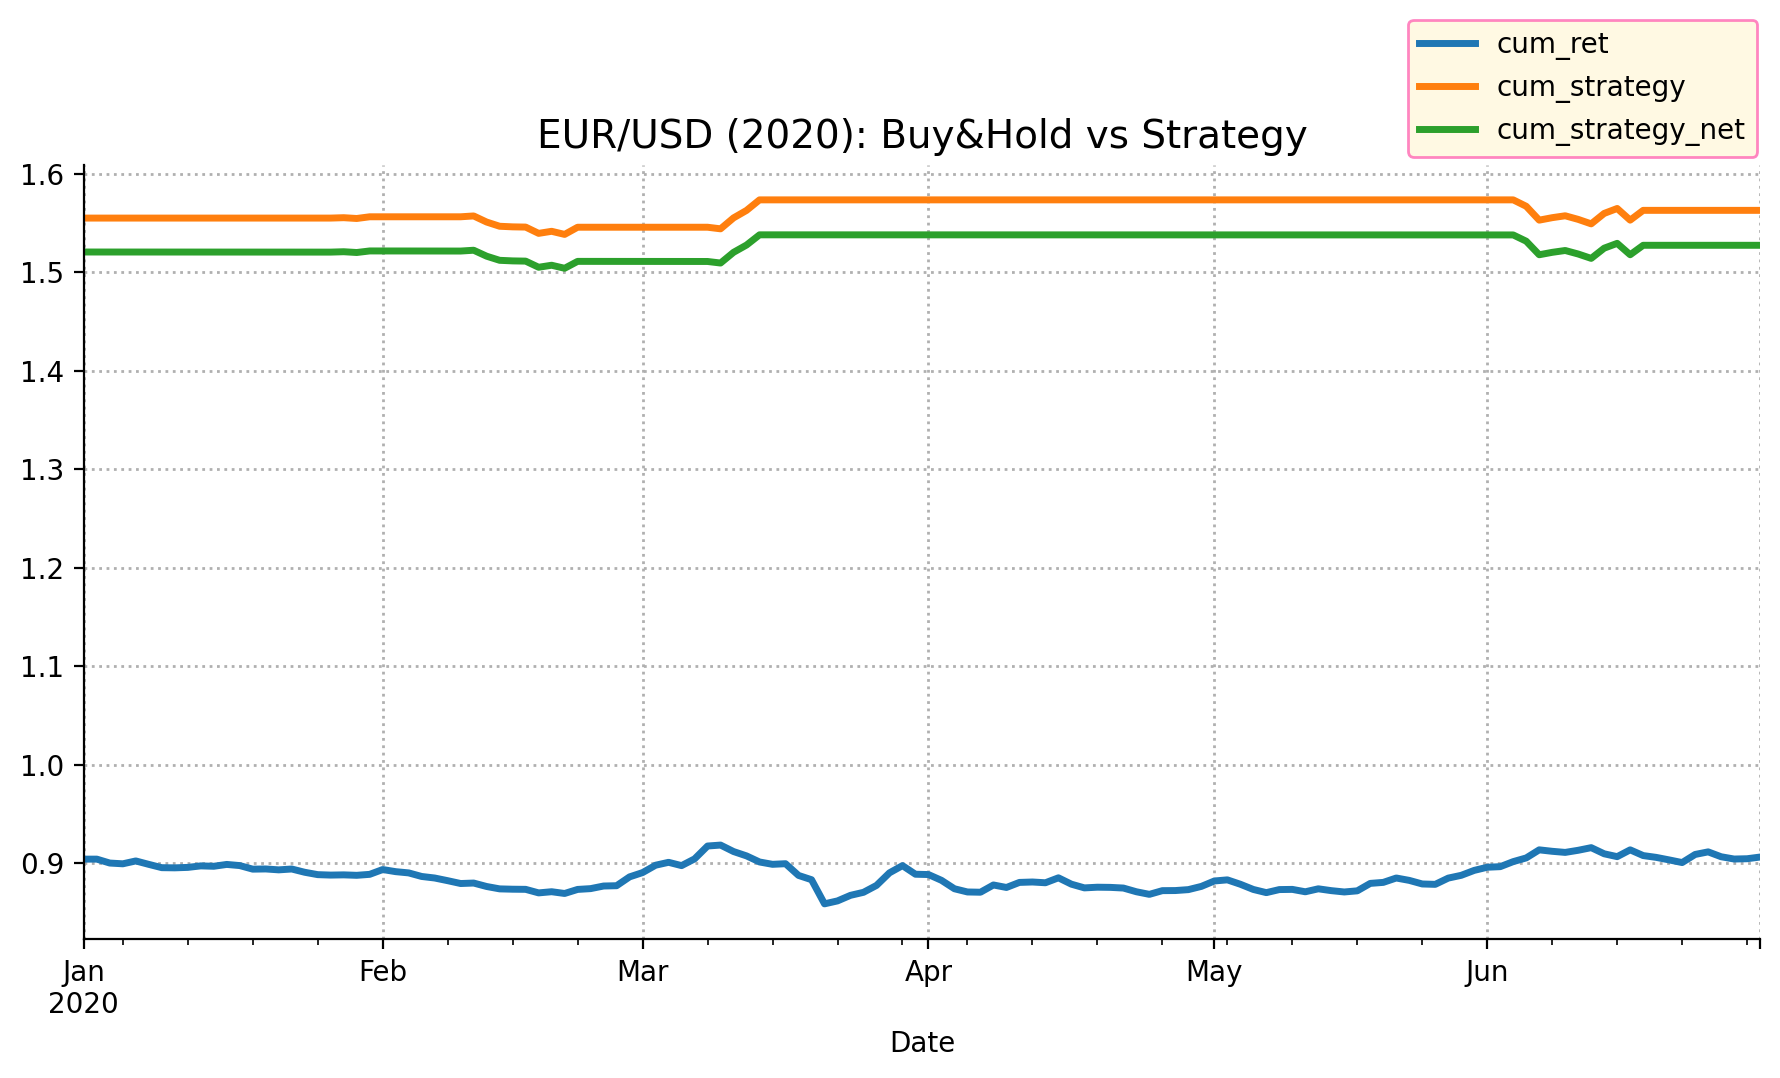

In [189]:
data.loc["2020" , ["cum_ret", "cum_strategy", "cum_strategy_net"]].plot(figsize = (9 , 5) , lw = 2.5).autoscale(enable=True, tight = True , axis = "x")
plt.gca().spines[["right" , "top"]].set_visible(False)
plt.title("EUR/USD (2020): Buy&Hold vs Strategy" , fontsize = 14)
plt.grid( ls = ":", lw = 1)
plt.tight_layout()
plt.legend(loc = (0.79,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
plt.show()

## Using the RSIBacktester Class

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brute
plt.style.use("seaborn-v0_8")

In [ ]:
pd.read_csv("forex_pairs.csv")

In [ ]:
from RSIBacktester import RSIBacktester as RSI

In [ ]:
ptc = 0.00007

In [ ]:
tester = RSI("EURUSD=X", periods = 20, rsi_upper = 70, rsi_lower = 30,
              start = "2004-01-01", end = "2020-06-30", tc = ptc)

In [ ]:
tester

In [ ]:
tester.data

In [ ]:
tester.test_strategy()

In [ ]:
tester.plot_results()

In [ ]:
tester.results

In [ ]:
tester.optimize_parameters((5, 20, 1), (65, 80, 1), (20, 35, 1)) # higher volatility

In [ ]:
tester.plot_results()

In [ ]:
tester.optimize_parameters((20, 50, 1), (75, 85, 1), (15, 25, 1)) # lower volatility

In [ ]:
tester.plot_results()

__USD / GBP__

In [ ]:
tester = RSI("USDGBP=X", periods = 20, rsi_upper = 70, rsi_lower = 30,
              start = "2004-01-01", end = "2020-06-30", tc = 0)

In [ ]:
tester.test_strategy()

In [ ]:
tester.plot_results()

In [ ]:
tester.optimize_parameters((5, 20, 1), (65, 80, 1), (20, 35, 1)) # high volatility

In [ ]:
tester.plot_results()

## Alternative Strategies and Interpretations

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brute
plt.style.use("seaborn-v0_8")
from RSIBacktester import RSIBacktester as RSI

In [ ]:
tester = RSI("EURUSD=X", periods = 20, rsi_upper = 70, rsi_lower = 30,
              start = "2004-01-01", end = "2020-06-30", tc = 0)

In [ ]:
alt = tester.data.dropna()
alt

Convergence: 
- if __Price__ reaches __higher highs__ -> __RSI__ reaches __higher highs__ (confirmation)
- if __Price__ reaches __lower lows__ -> __RSI__ reaches __lower lows__ (confirmation)

In [ ]:
alt.loc["03-2013":"06-2013", ["price", "RSI"]].plot(figsize = (12, 8), secondary_y = "RSI")
plt.show()

Divergence: 
- if __Price__ reaches __higher highs__ -> __RSI fails__ to reach higher highs (__Bearish Divergence__)
- if __Price__ reaches __lower lows__ -> __RSI fails__ to reach lower lows (__Bullish Divergence__)

In [ ]:
alt.loc["03-2016":"06-2016", ["price", "RSI"]].plot(figsize = (12, 8), secondary_y = "RSI")
plt.title("Bearish Divergence", fontsize = 15)
plt.show()

In [ ]:
alt.loc["05-2012":"11-2012", ["price", "RSI"]].plot(figsize = (12, 8), secondary_y = "RSI")
plt.title("Bullish Divergence", fontsize = 15)
plt.show()